# ODE Solvers: Accuracy, Stability, and Stiffness

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/caam37830-sci-comp/notes/blob/main/05_differential_equations/ode_solvers.ipynb)

In [Initial Value Problems](ode_initial.ipynb) we handed ODEs to `solve_ivp` and wrote
forward Euler by hand.  This section looks inside the black box.  Three questions decide
whether a method is any good for a given problem:

1. **Accuracy.** How fast does the error go to zero as the step size $h$ shrinks?
2. **Stability.** For which step sizes does the method give bounded answers at all?
3. **Cost.** How many evaluations of the right-hand side $f$ does it take to reach a
   given accuracy?

The answers explain the list of `method=` options in `solve_ivp`, and when to pick each.

In [1]:
import time
import unittest

import numpy as np
import scipy.sparse as sparse
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

## Order of accuracy

We need a test problem with a known solution.  The logistic equation from the last section,

$$ y' = y(1 - y), \qquad y(0) = 0.1, $$

has the exact solution $y(t) = 1/(1 + 9e^{-t})$.

Forward Euler takes the step $y_{n+1} = y_n + h f(t_n, y_n)$.  The exact solution
satisfies $y(t + h) = y(t) + h y'(t) + \tfrac{h^2}{2} y''(t) + \cdots$, so each step makes
a **local error** of size $O(h^2)$.  Reaching a fixed time $T$ takes $T/h$ steps, and the
local errors add up to a **global error** of size $O(h)$.  A method whose global error is
$O(h^p)$ is said to have **order $p$**, so forward Euler has order 1.

### Runge-Kutta methods

A Runge-Kutta method samples the slope $f$ at a few points inside each step and combines
the samples so that more terms of the Taylor series cancel.  The **midpoint method** takes
half an Euler step, evaluates the slope there, and uses that slope for the whole step:

$$
k_1 = f(t_n, y_n), \qquad
k_2 = f\!\left(t_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2} k_1\right), \qquad
y_{n+1} = y_n + h k_2 .
$$

The classical fourth-order method, **RK4**, uses four slopes:

$$
\begin{aligned}
k_1 &= f(t_n, y_n), & k_2 &= f\!\left(t_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2}k_1\right),\\
k_3 &= f\!\left(t_n + \tfrac{h}{2},\ y_n + \tfrac{h}{2}k_2\right), & k_4 &= f(t_n + h,\ y_n + h k_3),
\end{aligned}
\qquad
y_{n+1} = y_n + \tfrac{h}{6}\left(k_1 + 2k_2 + 2k_3 + k_4\right).
$$

Every explicit Runge-Kutta method has the same structure.  Stage $i$ evaluates $f$ at
time $t_n + c_i h$ and state $y_n + h\sum_{j<i} a_{ij} k_j$, and the step combines the
stages with weights $b_i$.  The coefficients are collected in a **Butcher tableau**

$$
\begin{array}{c|c}
c & A \\ \hline & b^\top
\end{array}
$$

so a single function can implement all of them.

In [2]:
def rk_step(f, t, y, h, tableau):
    """
    one step of the explicit Runge-Kutta method with Butcher tableau (A, b, c)
    """
    A, b, c = tableau
    k = []
    for i in range(len(b)):
        yi = y + h * sum(A[i][j] * k[j] for j in range(i))
        k.append(f(t + c[i] * h, yi))
    return y + h * sum(bi * ki for bi, ki in zip(b, k))


def rk_solve(f, t_span, y0, h, tableau):
    """
    integrate y' = f(t, y) over t_span with fixed step h

    returns arrays t (n+1,) and y (n+1, ...), a stripped-down solve_ivp
    """
    t0, t1 = t_span
    n = int(round((t1 - t0) / h))
    t = t0 + h * np.arange(n + 1)
    y = [np.asarray(y0, dtype=float)]
    for k in range(n):
        y.append(rk_step(f, t[k], y[-1], h, tableau))
    return t, np.array(y)


#            A                                               b                     c
EULER    = ([[0]],                                          [1],                  [0])
MIDPOINT = ([[0, 0], [1/2, 0]],                             [0, 1],               [0, 1/2])
RK4      = ([[0, 0, 0, 0], [1/2, 0, 0, 0], [0, 1/2, 0, 0], [0, 0, 1, 0]],
            [1/6, 1/3, 1/3, 1/6], [0, 1/2, 1/2, 1])

Now measure the error on a sequence of step sizes and read the order off the slope of a
log-log plot, as in [Convergence of Algorithms](../01_analysis/convergence.ipynb).  We
measure the largest error anywhere on $[0, 10]$, not just at the final time.

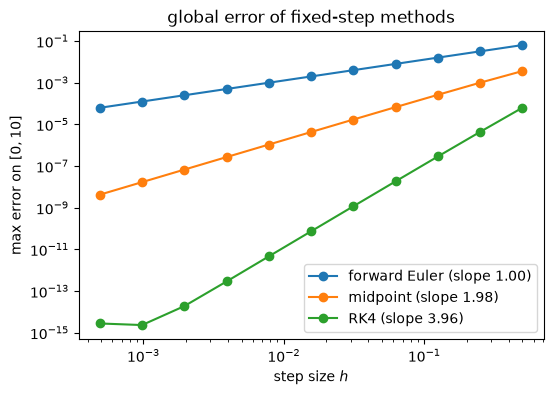

In [3]:
f = lambda t, y: y * (1 - y)
exact = lambda t: 1 / (1 + 9 * np.exp(-t))
T = 10.0
hs = 2.0 ** -np.arange(1, 12)

methods = {"forward Euler": EULER, "midpoint": MIDPOINT, "RK4": RK4}
errors = {}
for name, tableau in methods.items():
    errs = []
    for h in hs:
        t, y = rk_solve(f, (0, T), 0.1, h, tableau)
        errs.append(np.max(np.abs(y - exact(t))))
    errors[name] = np.array(errs)

plt.figure(figsize=(6, 4))
for name, err in errors.items():
    keep = err > 1e-12          # leave out the points sitting on the round-off floor
    p = np.polyfit(np.log(hs[keep]), np.log(err[keep]), 1)[0]
    plt.loglog(hs, err, 'o-', label=f'{name} (slope {p:.2f})')
plt.xlabel('step size $h$')
plt.ylabel('max error on $[0, 10]$')
plt.legend()
plt.title('global error of fixed-step methods')
plt.show()

The slopes are 1, 2 and 4, as promised.  RK4 runs into round-off around $10^{-15}$, where
shrinking $h$ stops helping (compare the error plot in
[Differentiation](../04_functions/differentiation.ipynb)).

### Accuracy per unit of work

Higher order costs more per step: RK4 evaluates $f$ four times per step, forward Euler
once.  The fair comparison is error against the total number of function evaluations, a
**work-precision diagram**.

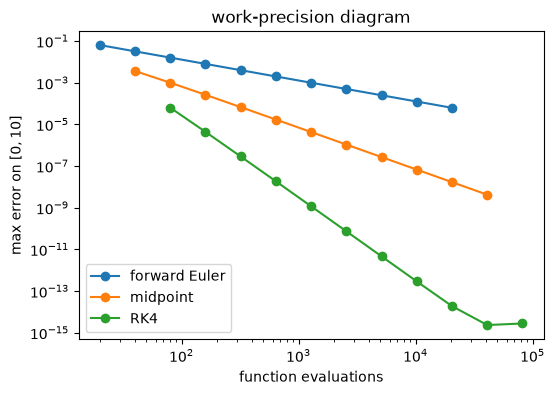

forward Euler :  20480 evaluations for an error below 1e-4
midpoint      :    320 evaluations for an error below 1e-4
RK4           :     80 evaluations for an error below 1e-4


In [4]:
stages = {"forward Euler": 1, "midpoint": 2, "RK4": 4}

plt.figure(figsize=(6, 4))
for name, err in errors.items():
    nfev = stages[name] * T / hs
    plt.loglog(nfev, err, 'o-', label=name)
plt.xlabel('function evaluations')
plt.ylabel('max error on $[0, 10]$')
plt.legend()
plt.title('work-precision diagram')
plt.show()

for name, err in errors.items():
    nfev = stages[name] * T / hs
    first = np.nonzero(err < 1e-4)[0][0]      # coarsest step with error below 1e-4
    print(f"{name:14}: {nfev[first]:6.0f} evaluations for an error below 1e-4")

Unless $f$ is very cheap or the accuracy requirement very loose, the higher-order method
wins by orders of magnitude.  This is why the default in `solve_ivp` is a fifth-order
method.

## Adaptive step size

A fixed step is wasteful when the solution changes at different rates at different times.
Take a planet on an elongated orbit around a star (units with $GM = 1$):

$$ \mathbf q'' = -\frac{\mathbf q}{\|\mathbf q\|^3}, $$

written as a first-order system for position $\mathbf q$ and velocity $\mathbf p$:
$\mathbf q' = \mathbf p$, $\mathbf p' = -\mathbf q/\|\mathbf q\|^3$.  The planet moves fast
near the star and slowly far away.  We start it at closest approach on an orbit of
eccentricity $e$ and period $2\pi$.

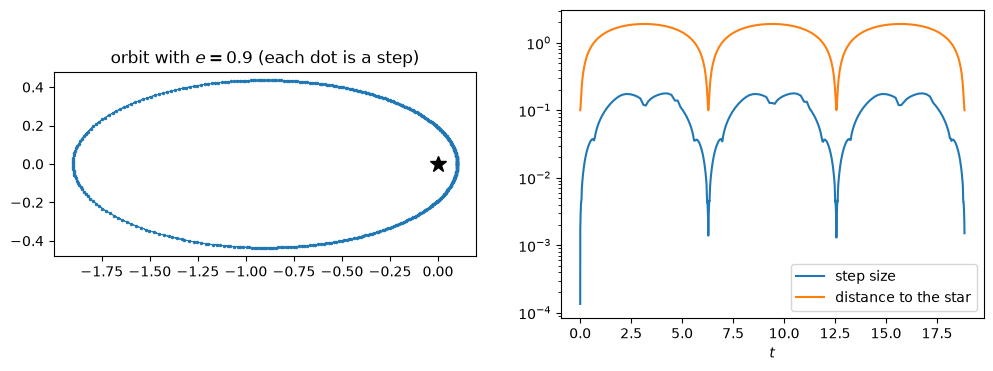

435 steps; largest / smallest step = 1321


In [5]:
def kepler(t, y):
    """
    right-hand side of the Kepler problem, y = (q1, q2, p1, p2)
    """
    q, p = y[:2], y[2:]
    return np.concatenate([p, -q / np.linalg.norm(q)**3])


def kepler_energy(y):
    """
    kinetic plus potential energy; y can be one state or a (4, n) array of states
    """
    q, p = y[:2], y[2:]
    return 0.5 * np.sum(p**2, axis=0) - 1 / np.linalg.norm(q, axis=0)


def kepler_initial(e):
    """
    closest approach on an orbit with eccentricity e and period 2*pi (energy -1/2)
    """
    return np.array([1 - e, 0.0, 0.0, np.sqrt((1 + e) / (1 - e))])


period = 2 * np.pi
y0 = kepler_initial(0.9)
sol = solve_ivp(kepler, (0, 3 * period), y0, rtol=1e-8, atol=1e-10)
steps = np.diff(sol.t)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(sol.y[0], sol.y[1], '.-', ms=3, lw=0.5)
ax[0].plot(0, 0, 'k*', ms=12)
ax[0].set_aspect('equal')
ax[0].set_title('orbit with $e = 0.9$ (each dot is a step)')
ax[1].semilogy(sol.t[:-1], steps, label='step size')
ax[1].semilogy(sol.t, np.linalg.norm(sol.y[:2], axis=0), label='distance to the star')
ax[1].set_xlabel('$t$')
ax[1].legend()
plt.show()

print(f"{len(steps)} steps; largest / smallest step = {steps.max() / steps.min():.0f}")

The step size tracks the distance to the star and varies by three orders of magnitude.  A
fixed step small enough for the closest approach would be wasted on the rest of the orbit.

**How does `solve_ivp` choose the step?**  The default method `RK45` (the Dormand-Prince
pair) is an **embedded** Runge-Kutta method.  From the same function evaluations it builds
both a fifth-order and a fourth-order approximation, and their difference estimates the
local error.  If the estimate is below `atol + rtol * |y|` the step is accepted and the
next one enlarged; otherwise the step is rejected and retried with a smaller $h$.  The
error estimate costs essentially nothing extra.

**The default tolerances are loose.**  Unless told otherwise, `solve_ivp` uses
`rtol=1e-3` and `atol=1e-6`.  These control the error made in *each step*, and those
errors accumulate.  The exact energy of the orbit is $-1/2$ forever; here is the energy
error after 100 orbits.

In [6]:
for rtol in [1e-3, 1e-6, 1e-9]:
    s = solve_ivp(kepler, (0, 100 * period), y0, rtol=rtol, atol=1e-3 * rtol)
    drift = kepler_energy(s.y[:, -1]) - kepler_energy(y0)
    r_end = np.linalg.norm(s.y[:2, -1])
    print(f"rtol = {rtol:.0e}: {s.nfev:7d} f evals, energy error {drift:+.1e}, "
          f"final distance {r_end:.2e}")

rtol = 1e-03:   22280 f evals, energy error -7.4e+07, final distance 6.73e-09


rtol = 1e-06:   50486 f evals, energy error -2.1e-04, final distance 4.27e-01


rtol = 1e-09:  145838 f evals, energy error +1.6e-07, final distance 1.00e-01


After a whole number of orbits the planet should be back at closest approach, at distance
$0.1$.  The first line uses the default tolerances: the computed planet has crashed into the
star (final distance essentially zero, energy off by many orders of magnitude), and
nothing warned us.  At `rtol=1e-6` the energy is fine to four digits but the planet is in
the wrong place on its orbit.  Always set `rtol` and `atol` yourself, and check that
the quantities you care about do not change when you tighten them.

## Stability

Accuracy is about the limit $h \to 0$.  Stability is about the step sizes you actually use.
The model problem is the linear test equation

$$ y' = \lambda y, \qquad y(0) = 1, $$

whose solution $e^{\lambda t}$ decays when $\operatorname{Re}\lambda < 0$.  Forward Euler
gives $y_{n+1} = (1 + h\lambda)\, y_n$, so $y_n = (1 + h\lambda)^n$, which decays only if
$|1 + h\lambda| \le 1$.  For real $\lambda < 0$ that means $h \le 2/|\lambda|$.

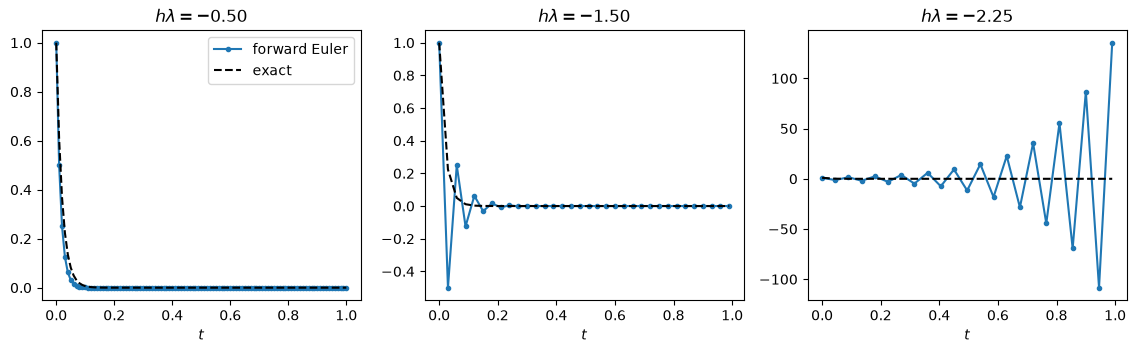

In [7]:
lam = -50.0
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, h in zip(ax, [0.01, 0.03, 0.045]):
    t, y = rk_solve(lambda t, y: lam * y, (0, 1), 1.0, h, EULER)
    a.plot(t, y, 'o-', ms=3, label='forward Euler')
    a.plot(t, np.exp(lam * t), 'k--', label='exact')
    a.set_title(f'$h\\lambda = {h * lam:.2f}$')
    a.set_xlabel('$t$')
ax[0].legend()
plt.show()

By $t = 1$ the exact solution is $e^{-50} \approx 10^{-22}$; there is nothing left to
resolve.  Forward Euler still blows up once $|h\lambda| > 2$.  Shrinking the step here
buys stability, not accuracy.

Applied to the test equation, one step of any Runge-Kutta method multiplies $y$ by a
**stability function** $R(z)$ evaluated at $z = h\lambda$.  For explicit methods $R$ is a
polynomial: $1 + z$ for forward Euler, $1 + z + z^2/2$ for the midpoint method, and
$1 + z + z^2/2 + z^3/6 + z^4/24$ for RK4, which are truncated Taylor series of $e^z$.  The
**stability region** is the set of complex $z$ with $|R(z)| \le 1$.  We allow complex
$\lambda$ because oscillating solutions (rotations, waves) have complex eigenvalues.

**Backward Euler** evaluates the slope at the *end* of the step,

$$ y_{n+1} = y_n + h f(t_{n+1}, y_{n+1}), $$

so for the test equation $y_{n+1} = y_n / (1 - h\lambda)$ and $R(z) = 1/(1 - z)$.

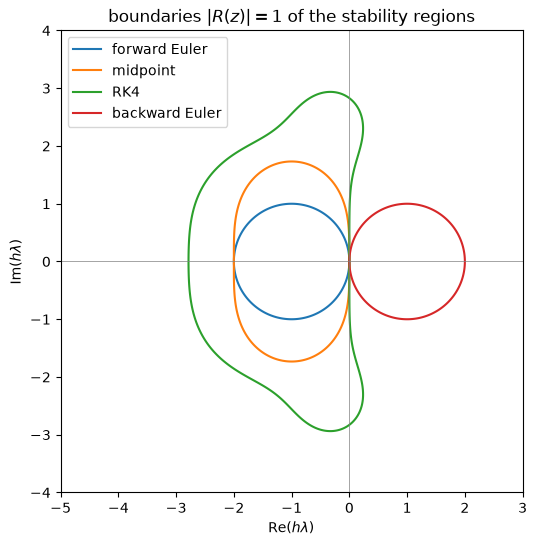

In [8]:
xr, xi = np.meshgrid(np.linspace(-5, 3, 400), np.linspace(-4, 4, 400))
z = xr + 1j * xi
R = {
    "forward Euler": 1 + z,
    "midpoint": 1 + z + z**2 / 2,
    "RK4": 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24,
    "backward Euler": 1 / (1 - z),
}

fig, ax = plt.subplots(figsize=(6, 6))
for (name, Rz), color in zip(R.items(), ['C0', 'C1', 'C2', 'C3']):
    ax.contour(xr, xi, np.abs(Rz), levels=[1], colors=color)
    ax.plot([], [], color=color, label=name)       # legend entry for the contour
ax.axhline(0, color='gray', lw=0.5)
ax.axvline(0, color='gray', lw=0.5)
ax.set_aspect('equal')
ax.set_xlabel(r'Re$(h\lambda)$')
ax.set_ylabel(r'Im$(h\lambda)$')
ax.legend(loc='upper left')
ax.set_title('boundaries $|R(z)| = 1$ of the stability regions')
plt.show()

For the explicit methods the stable region is the inside of each curve.  Forward Euler's
is the disk of radius 1 centered at $-1$; RK4's reaches to about $-2.79$ on the real axis.
Every explicit method has a bounded stability region, since a polynomial blows up at
infinity.

For backward Euler the stable region is the *outside* of the circle around $z = 1$.  It
contains the entire left half-plane, so the decaying test equation is handled stably with
any step size.  Methods with this property are called **A-stable**.

The price is that $y_{n+1}$ appears on both sides of the update, so every step requires
solving an equation.  For a system $y' = f(t, y)$ we solve
$G(Y) = Y - y_n - h f(t_{n+1}, Y) = 0$ with Newton's method
([Root Finding](../04_functions/roots.ipynb)).  The Newton matrix is $I - hJ$, where
$J = \partial f/\partial y$ is the Jacobian of $f$.

In [9]:
def backward_euler(f, jac, t_span, y0, h, newton_tol=1e-12, max_newton=20):
    """
    backward Euler with fixed step h

    each step solves Y - y_n - h f(t_{n+1}, Y) = 0 by Newton's method;
    jac(t, y) returns the Jacobian matrix of f with respect to y
    """
    t0, t1 = t_span
    n = int(round((t1 - t0) / h))
    t = t0 + h * np.arange(n + 1)
    y = [np.atleast_1d(np.asarray(y0, dtype=float))]
    I = np.eye(len(y[0]))
    for k in range(n):
        Y = y[-1].copy()                  # initial guess: the previous value
        for _ in range(max_newton):
            G = Y - y[-1] - h * f(t[k + 1], Y)
            dY = np.linalg.solve(I - h * jac(t[k + 1], Y), -G)
            Y = Y + dY
            if np.linalg.norm(dY) <= newton_tol * (1 + np.linalg.norm(Y)):
                break
        y.append(Y)
    return t, np.array(y)

## Stiffness

A problem is **stiff** when the step size of an explicit method is limited by stability
rather than by accuracy.  The usual cause is a system that contains some very fast,
strongly damped components alongside the slow behavior you actually want to follow.  The
fast components die out almost immediately, but an explicit method must still keep
$h\lambda$ inside its stability region for them, at every step, forever.

A clean example, due to Prothero and Robinson:

$$ y' = \lambda\,\bigl(y - \cos t\bigr) - \sin t, \qquad y(0) = 1. $$

The exact solution is $y(t) = \cos t$ for every $\lambda$, a smooth and slowly varying
function.  But any deviation from $\cos t$ decays like $e^{\lambda t}$, and with
$\lambda = -10^4$ an explicit method needs $h \lesssim 3 \times 10^{-4}$ no matter how
smooth the solution is.

In [10]:
lam = -1e4
f_pr = lambda t, y: lam * (y - np.cos(t)) - np.sin(t)
jac_pr = lambda t, y: np.array([[lam]])

print(f"{'method':8} {'steps':>7} {'f evals':>8} {'max error':>10} {'time':>8}")
for method in ["RK45", "DOP853", "Radau", "BDF", "LSODA"]:
    start = time.perf_counter()
    s = solve_ivp(f_pr, (0, 10), [1.0], method=method, rtol=1e-6, atol=1e-9)
    elapsed = time.perf_counter() - start
    err = np.max(np.abs(s.y[0] - np.cos(s.t)))
    print(f"{method:8} {len(s.t) - 1:7d} {s.nfev:8d} {err:10.1e} {elapsed:7.3f}s")

method     steps  f evals  max error     time


RK45       30209   202160    1.1e-06   0.818s


DOP853     15641   187754    1.3e-06   0.691s
Radau         21      172    9.8e-07   0.003s
BDF          139      356    3.6e-08   0.008s
LSODA        222      463    7.0e-07   0.001s


All five methods reach the same accuracy.  The explicit methods `RK45` and `DOP853` need
tens of thousands of steps, almost all of them spent keeping a component that no longer
exists stable.  The implicit methods `Radau` and `BDF` need between twenty and a hundred
or so.
`LSODA` monitors the problem and switches to an implicit method when it detects
stiffness.

Our backward Euler, with steps of $0.1$ and $0.01$:

In [11]:
for h in [0.1, 0.01]:
    t, y = backward_euler(f_pr, jac_pr, (0, 10), 1.0, h)
    print(f"backward Euler, h = {h}: {len(t) - 1:5d} steps, "
          f"max error {np.max(np.abs(y[:, 0] - np.cos(t))):.1e}")

t, y = rk_solve(f_pr, (0, 0.5), 1.0, 0.1, EULER)
print("\nforward Euler, h = 0.1:", y)

backward Euler, h = 0.1:   100 steps, max error 5.0e-06
backward Euler, h = 0.01:  1000 steps, max error 5.0e-07

forward Euler, h = 0.1: [ 1.00000000e+00  1.00000000e+00 -4.00581806e+00  4.98185896e+03
 -4.97592179e+06  4.97094679e+09]


Backward Euler is only first order, so it needs a hundred steps for an error of
$5 \times 10^{-6}$, but it is stable.  Forward Euler with the same step multiplies each
error by $1 + h\lambda = -999$ per step.

### A chemical example

Stiffness is the norm, not the exception, in chemical kinetics.  Robertson's reaction
system is a standard test problem:

$$
\begin{aligned}
y_1' &= -0.04\, y_1 + 10^4\, y_2 y_3\\
y_2' &= 0.04\, y_1 - 10^4\, y_2 y_3 - 3 \times 10^7\, y_2^2\\
y_3' &= 3 \times 10^7\, y_2^2
\end{aligned}
\qquad y(0) = (1, 0, 0).
$$

The rate constants span nine orders of magnitude.  The species $y_2$ stays below
$10^{-4}$, so it needs its own absolute tolerance: the default `atol=1e-6` would let the
solver ignore it entirely.

RK45  to t = 40:  34542 steps, 0.86s
BDF   to t = 40:    170 steps, 0.01s
BDF   to t = 100000:    383 steps, 0.02s


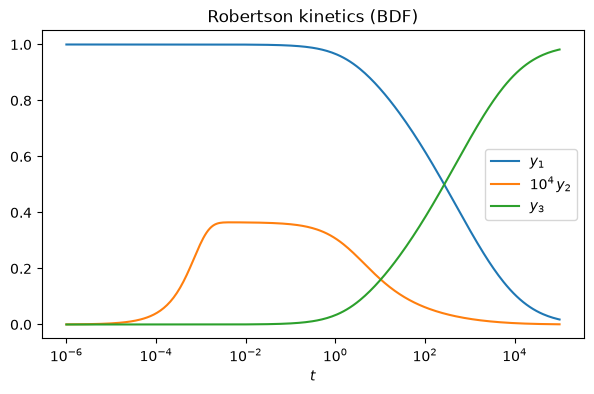

In [12]:
def robertson(t, y):
    y1, y2, y3 = y
    return [-0.04 * y1 + 1e4 * y2 * y3,
            0.04 * y1 - 1e4 * y2 * y3 - 3e7 * y2**2,
            3e7 * y2**2]


atol = [1e-8, 1e-14, 1e-8]
for method, T_end in [("RK45", 40), ("BDF", 40), ("BDF", 1e5)]:
    start = time.perf_counter()
    s = solve_ivp(robertson, (0, T_end), [1, 0, 0], method=method, rtol=1e-6, atol=atol)
    print(f"{method:5} to t = {T_end:g}: {len(s.t) - 1:6d} steps, "
          f"{time.perf_counter() - start:.2f}s")

t_plot = np.logspace(-6, 5, 300)
s = solve_ivp(robertson, (0, 1e5), [1, 0, 0], method="BDF", rtol=1e-6, atol=atol,
              t_eval=t_plot)
plt.figure(figsize=(7, 4))
plt.semilogx(s.t, s.y[0], label='$y_1$')
plt.semilogx(s.t, 1e4 * s.y[1], label=r'$10^4\, y_2$')
plt.semilogx(s.t, s.y[2], label='$y_3$')
plt.xlabel('$t$')
plt.legend()
plt.title('Robertson kinetics (BDF)')
plt.show()

`RK45` needs tens of thousands of steps just to reach $t = 40$; `BDF` covers the whole
range up to $t = 10^5$ in a few hundred.

### Semi-discretized PDEs are stiff

The most common source of stiffness in scientific computing is a PDE discretized in space.
The diffusion equation $u_t = u_{xx}$ on $n$ grid points becomes the linear system
$\mathbf u' = A \mathbf u$, where $A$ is the second-difference matrix (we derive it in
[Time-Dependent PDEs](pde_time_evolution.ipynb)).  The eigenvalues of $A$ reach down to
about $-4/\Delta x^2$, so refining the mesh makes the problem stiffer.

In [13]:
def second_difference(n):
    """
    second-difference matrix on n interior points of [0, 1], ends held at zero
    """
    dx = 1 / (n + 1)
    return sparse.diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(n, n), format='csr') / dx**2


print(f"{'n':>4} {'RK45 steps':>11} {'BDF steps':>10}")
for n in [50, 100, 200]:
    A = second_difference(n)
    x = np.linspace(0, 1, n + 2)[1:-1]
    u0 = np.sin(np.pi * x) + 0.5 * np.sin(3 * np.pi * x)
    rk = solve_ivp(lambda t, u: A @ u, (0, 0.5), u0, method="RK45", rtol=1e-6, atol=1e-9)
    bdf = solve_ivp(lambda t, u: A @ u, (0, 0.5), u0, method="BDF", rtol=1e-6, atol=1e-9,
                    jac=A)
    print(f"{n:4d} {len(rk.t) - 1:11d} {len(bdf.t) - 1:10d}")

   n  RK45 steps  BDF steps
  50        1560        112


 100        6135        112


 200       24380        112


Each time the mesh is refined by a factor of 2, `RK45` needs 4 times as many steps; that
is the $\Delta t \lesssim \Delta x^2$ restriction of the explicit method showing up inside
an adaptive solver.  `BDF` takes the same number of steps on every mesh.

**Supply the Jacobian.**  Implicit methods solve linear systems with matrices like
$I - h\gamma J$.  If you do not pass `jac`, `Radau` and `BDF` approximate $J$ by finite
differences, which costs one evaluation of $f$ per unknown and produces a dense matrix.
For large systems pass `jac=` (a sparse matrix if $J$ is sparse, as above) or at least
`jac_sparsity=` with the sparsity pattern.

## Long-time integration and conservation

For a conservative system like the orbit above, small errors in each step can add up in a
systematic direction.  Here is RK4 with a fixed step on an orbit of eccentricity 0.5,
compared with the **velocity Verlet** method:

$$
\mathbf p_{n+1/2} = \mathbf p_n + \tfrac{h}{2}\, \mathbf a(\mathbf q_n), \qquad
\mathbf q_{n+1} = \mathbf q_n + h\, \mathbf p_{n+1/2}, \qquad
\mathbf p_{n+1} = \mathbf p_{n+1/2} + \tfrac{h}{2}\, \mathbf a(\mathbf q_{n+1}),
$$

where $\mathbf a(\mathbf q) = -\mathbf q/\|\mathbf q\|^3$ is the acceleration.  Verlet is
only second order, and the acceleration at the end of one step is reused at the start of
the next, so it costs one force evaluation per step against four for RK4.

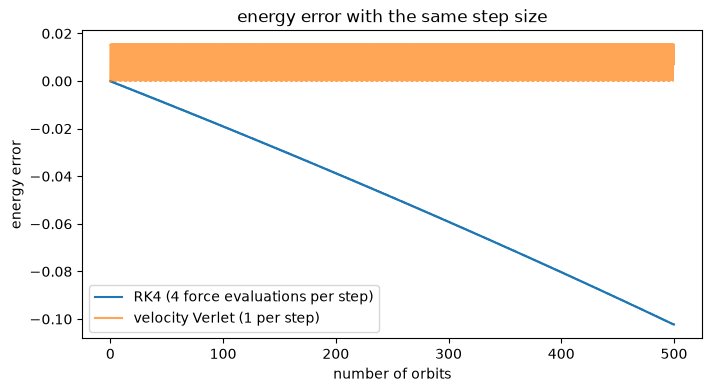

In [14]:
def velocity_verlet(accel, q0, p0, h, n):
    """
    n steps of velocity Verlet for q'' = accel(q); returns positions and velocities
    """
    q, p = np.array(q0, dtype=float), np.array(p0, dtype=float)
    Q, P = [q], [p]
    a = accel(q)
    for _ in range(n):
        p_half = p + 0.5 * h * a
        q = q + h * p_half
        a = accel(q)
        p = p_half + 0.5 * h * a
        Q.append(q)
        P.append(p)
    return np.array(Q), np.array(P)


y0 = kepler_initial(0.5)
h = period / 60
n = 500 * 60                               # 500 orbits, 60 steps per orbit
t = h * np.arange(n + 1)

Q, P = velocity_verlet(lambda q: -q / np.linalg.norm(q)**3, y0[:2], y0[2:], h, n)
E_verlet = kepler_energy(np.vstack([Q.T, P.T]))

_, Y = rk_solve(kepler, (0, n * h), y0, h, RK4)
E_rk4 = kepler_energy(Y.T)

plt.figure(figsize=(8, 4))
plt.plot(t / period, E_rk4 + 0.5, label='RK4 (4 force evaluations per step)')
plt.plot(t / period, E_verlet + 0.5, label='velocity Verlet (1 per step)', alpha=0.7)
plt.xlabel('number of orbits')
plt.ylabel('energy error')
plt.legend()
plt.title('energy error with the same step size')
plt.show()

RK4 has the smaller error over the first few orbits, as its higher order suggests, but its
energy error drifts steadily, and the drift never stops.  The Verlet error oscillates
within a fixed band and does not grow, even though the method is cheaper and of lower
order.

The reason is that Verlet is **symplectic**: each step is a symplectic map, the same kind
of map that the exact flow of a Hamiltonian system is.  One consequence is that the
numerical solution almost exactly conserves a slightly modified energy, over extremely
long times, so the true energy cannot drift away.  For long simulations of conservative systems (planetary dynamics,
molecular dynamics) symplectic integrators are the standard choice.  None of the methods
in `solve_ivp` is symplectic, so if you run one of them over many periods, monitor the
energy.

## Choosing a method in `solve_ivp`

| `method` | type | order | use it for |
|:--|:--|:--|:--|
| `RK45` (default) | explicit Runge-Kutta, adaptive | 5(4) | non-stiff problems, moderate accuracy |
| `DOP853` | explicit Runge-Kutta, adaptive | 8 | non-stiff problems, high accuracy |
| `Radau` | implicit Runge-Kutta | 5 | stiff problems, high accuracy |
| `BDF` | implicit multistep | 1 to 5 | stiff problems, large systems |
| `LSODA` | switches between Adams and BDF | variable | when you do not know whether the problem is stiff |

Some rules of thumb:

* Set `rtol` and `atol` explicitly, and give `atol` per component when the components have
  very different sizes.
* Check an answer by tightening the tolerances and confirming that nothing you care about
  changes.
* If `RK45` takes a huge number of steps on a solution that looks smooth, the problem is
  probably stiff.  Switch to `BDF` or `Radau` and pass the Jacobian.
* For long runs of conservative systems, monitor the conserved quantities.

## Testing an ODE solver

The most informative unit test for a solver is a convergence test (see
[Unit Testing](../10_computing/unittest.ipynb)).  A wrong coefficient in a Butcher tableau
usually still produces plausible-looking solutions, but it almost always lowers the order,
and a test of the order catches it immediately.

In [15]:
def observed_order(tableau, hs=2.0 ** -np.arange(3, 8)):
    """
    slope of log(max error) against log(h) on the logistic test problem
    """
    errs = []
    for h in hs:
        t, y = rk_solve(f, (0, 2.0), 0.1, h, tableau)
        errs.append(np.max(np.abs(y - exact(t))))
    return np.polyfit(np.log(hs), np.log(errs), 1)[0]


class TestRungeKutta(unittest.TestCase):

    def test_order(self):
        for tableau, p in [(EULER, 1), (MIDPOINT, 2), (RK4, 4)]:
            self.assertAlmostEqual(observed_order(tableau), p, delta=0.15)

    def test_constant_slope(self):
        # y' = 1 has solution y = t, which every consistent method gets exactly
        for tableau in [EULER, MIDPOINT, RK4]:
            t, y = rk_solve(lambda t, y: 1.0, (0, 1), 0.0, 0.1, tableau)
            self.assertAlmostEqual(y[-1], 1.0, places=12)


unittest.main(argv=['first-arg-is-ignored'], exit=False);

.

.

----------------------------------------------------------------------
Ran 2 tests in 0.004s

OK


Try changing one of the `1/3` weights of `RK4` to `0.3` and running the tests again.

## Exercises

### Exercise 1

The "3/8 rule" is another fourth-order Runge-Kutta method, with tableau

$$
\begin{array}{c|cccc}
0 & & & & \\
1/3 & 1/3 & & & \\
2/3 & -1/3 & 1 & & \\
1 & 1 & -1 & 1 & \\ \hline
 & 1/8 & 3/8 & 3/8 & 1/8
\end{array}
$$

Add it to `rk_solve`, verify that it has order 4, and compare its error constant with that
of classical RK4 on the logistic problem.  Does it have the same stability function?

In [16]:
# Your code here

### Exercise 2

For $y' = -100 y$, find the largest stable fixed step size for forward Euler, the midpoint
method and RK4 experimentally (for example by bisection on $h$, declaring a run unstable
if $|y|$ grows over 1000 steps).  Compare with the points where the stability regions
above cross the negative real axis.

In [17]:
# Your code here

### Exercise 3

The **trapezoidal rule** (Crank-Nicolson) is

$$ y_{n+1} = y_n + \tfrac{h}{2}\bigl(f(t_n, y_n) + f(t_{n+1}, y_{n+1})\bigr). $$

1. Find its stability function $R(z)$ and show that it is A-stable.  What is its order?
2. Implement it (modify `backward_euler`) and solve the Prothero-Robinson problem with
   $h = 0.1$ starting from $y(0) = 2$ instead of $1$, which puts the fast component in at
   full strength.  Compare with backward Euler over the first few steps.
3. Explain what you see using the limit of $R(z)$ as $z \to -\infty$ for each method.
   (A method with $R(z) \to 0$ there is called **L-stable**.)

In [18]:
# Your code here

### Exercise 4

The **Van der Pol oscillator**

$$ x'' - \mu (1 - x^2)\, x' + x = 0 $$

becomes stiff as $\mu$ grows.  Write it as a first-order system and solve it on
$t \in [0, 3\mu]$ for $\mu = 1, 10, 100, 1000$ with `RK45`, `BDF`, and `LSODA`, using
`rtol=1e-6`.  Tabulate the number of function evaluations and the run time.  Around which
$\mu$ does the stiff solver start to win?  Plot $x(t)$ for $\mu = 1000$ and describe the
two time scales you see.

In [19]:
# Your code here

### Exercise 5

Repeat the long-time orbit experiment at equal cost: give RK4 a step four times larger
than Verlet's so both use the same number of force evaluations.  Besides the energy, look
at the *phase* error, the angle between the computed and the exact position after 500
orbits.  Which method is better for which quantity?

In [20]:
# Your code here